# Proyek Machine Learning: Prediksi Telco Customer Churn
Notebook ini berisi tahapan lengkap mulai dari Data Loading, Data Cleaning & Transformation, Exploratory Data Analysis (EDA), Data Splitting, hingga Pembangunan Modeling untuk memprediksi pelanggan yang berpotensi melakukan *churn* (berhenti berlangganan).

In [1]:
# Import library yang dibutuhkan untuk pengolahan data, visualisasi, dan modeling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan visualisasi seaborn
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading
Pada tahap ini, kita memuat dataset dari file CSV ke dalam Pandas DataFrame dan melakukan pemeriksaan awal struktur data, informasi kolom, serta beberapa baris pertama data.

In [2]:
# Memuat dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Menampilkan 5 baris pertama dataset
display(df.head())

# Menampilkan informasi ringkas mengenai dataset (tipe data dan missing values)
print("\nInformasi Dataset:")
df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null  

## 2. Data Cleaning & Transformation
Tahapan ini meliputi:
1. Mengonversi kolom `TotalCharges` ke tipe numerik dan menangani nilai kosong (*missing values*).
2. Menghapus kolom yang tidak relevan seperti `customerID`.
3. Mengubah variabel target (`Churn`) dan fitur kategorikal menjadi format numerik.
4. Melakukan penskalaan (*scaling*) pada fitur numerik.

In [3]:
# 1. Menangani kolom TotalCharges yang memiliki spasi/nilai kosong tersembunyi
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Mengisi missing values pada TotalCharges dengan nilai median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# 2. Menghapus kolom customerID karena merupakan identitas unik dan tidak berpengaruh pada prediksi
df.drop('customerID', axis=1, inplace=True)

# 3. Mengubah target Churn ('Yes'/'No') menjadi biner (1 dan 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Mengubah fitur kategorikal menjadi One-Hot Encoding
cat_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("Dimensi dataset setelah cleaning & transformation:", df_encoded.shape)
df_encoded.head()

Dimensi dataset setelah cleaning & transformation: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


## 3. Exploratory Data Analysis (EDA)
Pada bagian ini, kita melakukan analisis eksploratif untuk memahami distribusi dari variabel target (*Churn*) serta melihat hubungan antara beberapa fitur utama dengan keputusan pelanggan untuk berhenti berlangganan.

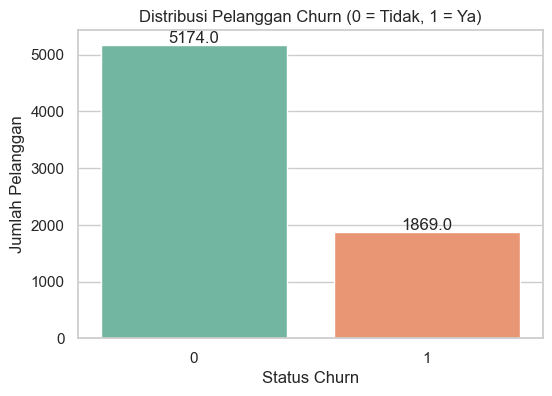

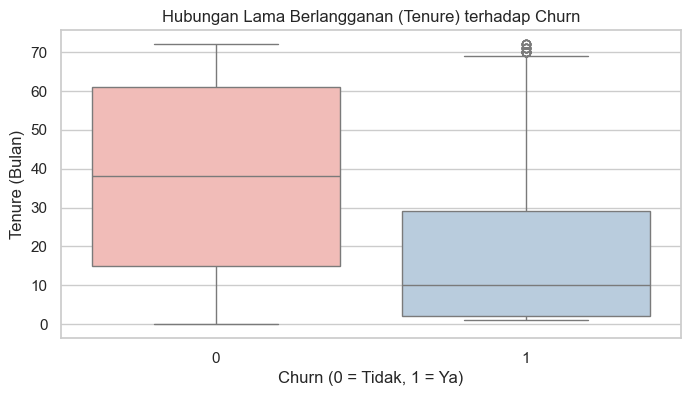

In [4]:
# Visualisasi Distribusi Target (Churn)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Distribusi Pelanggan Churn (0 = Tidak, 1 = Ya)')
plt.xlabel('Status Churn')
plt.ylabel('Jumlah Pelanggan')
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

# Visualisasi hubungan Tenure (lama berlangganan) dengan Churn
plt.figure(figsize=(8, 4))
sns.boxplot(x='Churn', y='tenure', data=df, palette='Pastel1')
plt.title('Hubungan Lama Berlangganan (Tenure) terhadap Churn')
plt.xlabel('Churn (0 = Tidak, 1 = Ya)')
plt.ylabel('Tenure (Bulan)')
plt.show()

### Korelasi Fitur Terhadap Churn
Kita melihat korelasi antar fitur numerik untuk mengetahui faktor apa saja yang paling erat kaitannya dengan keputusan pelanggan berhenti berlangganan.

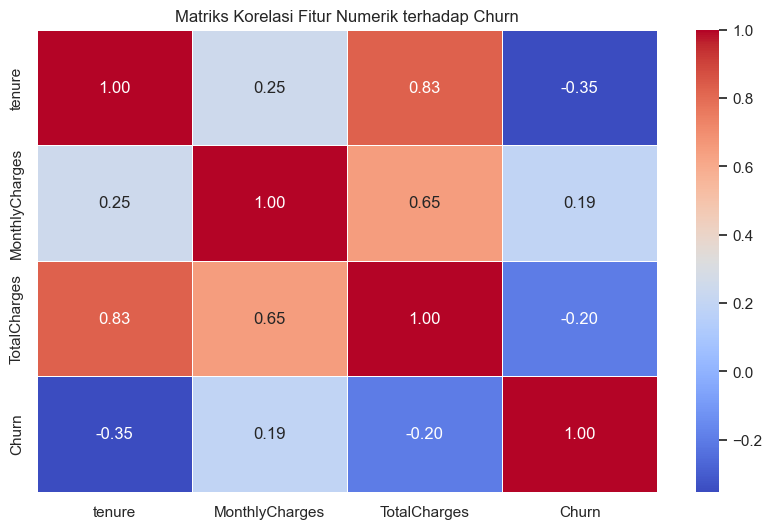

In [11]:
plt.figure(figsize=(10, 6))
# Mengambil kolom numerik pada df_encoded untuk melihat korelasi
corr = df_encoded[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriks Korelasi Fitur Numerik terhadap Churn')
plt.show()

## 4. Data Splitting
Sebelum melakukan pemodelan, kita memisahkan dataset menjadi fitur independen (`X`) dan variabel target (`y`), lalu membaginya menjadi data latih (*training set*) dan data uji (*testing set*) dengan rasio 80:20 serta menerapkan *stratify* agar proporsi kelas seimbang. Selain itu, fitur numerik diskalakan menggunakan `StandardScaler`.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Memisahkan Fitur dan Target
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Membagi Data Train dan Test (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Melakukan Scaling pada Fitur Numerik
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"Jumlah data latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah data uji (X_test): {X_test.shape[0]} baris")

Jumlah data latih (X_train): 5634 baris
Jumlah data uji (X_test): 1409 baris


In [9]:
# Menangani nilai NaN yang tersisa pada X_train dan X_test
# Untuk kolom numerik diisi dengan median, untuk kolom lain/kategorikal diisi dengan modus atau 0
X_train.fillna(X_train.median(numeric_only=True), inplace=True)
X_test.fillna(X_test.median(numeric_only=True), inplace=True)

# Jika masih ada sisa NaN di kolom lain, isi dengan 0
X_train.fillna(0, inplace=True)
X_test.fillna(0, inplace=True)

print("Jumlah NaN di X_train setelah dibersihkan:", X_train.isnull().sum().sum())
print("Jumlah NaN di X_test setelah dibersihkan:", X_test.isnull().sum().sum())

Jumlah NaN di X_train setelah dibersihkan: 0
Jumlah NaN di X_test setelah dibersihkan: 0


## 5. Pembangunan Modeling (Modeling)
Pada tahap ini, kita membangun model Machine Learning menggunakan **Logistic Regression** sebagai model *baseline* dan **Random Forest Classifier** sebagai model pembanding yang lebih kompleks. Setelah itu, kita mengevaluasi performa kedua model menggunakan akurasi, *confusion matrix*, dan *classification report*.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Inisialisasi Model
model_lr = LogisticRegression(random_state=42)
model_rf = RandomForestClassifier(random_state=42, n_estimators=100)

# Melatih Model (Training)
model_lr.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

# Prediksi Menggunakan Data Uji
y_pred_lr = model_lr.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

# Evaluasi Model Logistic Regression
print("--- EVALUASI: LOGISTIC REGRESSION ---")
print("Akurasi:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

# Evaluasi Model Random Forest
print("\n--- EVALUASI: RANDOM FOREST ---")
print("Akurasi:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

--- EVALUASI: LOGISTIC REGRESSION ---
Akurasi: 0.8062455642299503

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


--- EVALUASI: RANDOM FOREST ---
Akurasi: 0.7856635911994322

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409



### Evaluasi Confusion Matrix
Confusion Matrix digunakan untuk melihat secara detail jumlah prediksi yang benar (True Positive / True Negative) dan prediksi yang salah (False Positive / False Negative) dari model Random Forest.

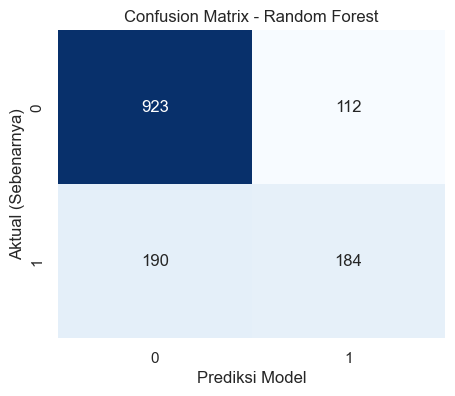

In [12]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung confusion matrix untuk Random Forest
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual (Sebenarnya)')
plt.show()

## 6. Kesimpulan
1. **Data Cleaning & Transformation** berhasil mengatasi nilai kosong pada `TotalCharges` dan mengonversi seluruh variabel kategorikal ke bentuk biner agar dapat dibaca oleh algoritma.
2. **EDA** memperlihatkan bahwa pelanggan dengan *tenure* (lama berlangganan) yang lebih pendek memiliki kecenderungan *churn* yang lebih tinggi.
3. **Modeling** menunjukkan perbandingan performa antara Logistic Regression dan Random Forest. Anda dapat menggunakan metrik *F1-Score* dan *Recall* pada laporan akhir untuk melihat kemampuan model dalam memprediksi pelanggan yang benar-benar akan *churn*.